# Dissecting non-coding *TAL1* mutations in T-ALL

T-cell acute lymphoblastic leukemia (T-ALL) often arises when somatic mutations ectopically activate the transcription factor *TAL1* in thymocyte progenitors where the locus is normally silent. Whole-genome sequencing of leukemias from individuals with T-ALL and T-ALL cell lines has mapped recurrent non-coding insertions, deletions, and single-nucleotide variants across three cis-regulatory sites flanking *TAL1* ([Mansour et al., *Science* 2014](https://doi.org/10.1126/science.1259037); [Liu et al., *Nature Genetics* 2017](https://doi.org/10.1038/ng.3909); [Liu et al., *Nature Genetics* 2020](https://doi.org/10.1038/s41588-020-0659-5); [Smith et al., *Haematologica* 2023](https://doi.org/10.3324/haematol.2022.281583)).

Following [Avsec et al., *Nature* 2026](https://doi.org/10.1038/s41586-025-10014-0), we use AlphaGenome 2 to ask three questions:

1. **Where** do published T-ALL non-coding mutations fall relative to *TAL1*?
2. **How** does a single oncogenic insertion (`chr1:47239296:C>ACG`) remodel RNA-seq, DNase-seq, and histone modification tracks across the locus?
3. **Is the effect sequence-specific**, or would random insertions of the same length at the same positions produce comparable activation?

In [1]:
# @title Install AlphaGenome

# @markdown Run this cell to install AlphaGenome.
from IPython.display import clear_output
! pip install alphagenome
clear_output()

## Set up

Store your API key in Colab Secrets for persistent access across sessions (see [Installation](https://www.alphagenomedocs.com/installation.html#add-api-key-to-secrets)). We initialize the AlphaGenome 2 client (`dna_client.create`) and load canonical MANE Select protein-coding transcripts from GENCODE v46 (GRCh38) to visualize surrounding genes.

In [2]:
# @title Imports
import io

from alphagenome import colab_utils
from alphagenome.data import gene_annotation
from alphagenome.data import genome
from alphagenome.data import transcript
from alphagenome.models.v2 import dna_client
from alphagenome.models.v2 import variant_scorers
from alphagenome.visualization import plot_components
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd

dna_model = dna_client.create(colab_utils.get_api_key())

gtf = pd.read_feather(
    'https://storage.googleapis.com/alphagenome/reference/gencode/hg38/gencode.v46.annotation.gtf.gz.feather'
)
gtf_mane = gene_annotation.filter_to_mane_select_transcript(gtf)
transcript_extractor = transcript.TranscriptExtractor(gtf_mane)

## Published non-coding T-ALL variants at the *TAL1* locus

We compile 32 somatic T-ALL mutations (`15` unique alleles) across three regulatory sites around *TAL1*, which is transcribed on the minus (`-`) strand from `chr1:47,232,373` to `chr1:47,216,290`:

- **5' MuTE neo-enhancer** (`chr1:47,239,291` to `chr1:47,239,296`, ~7 kb upstream of the transcription start site): short 1-bp to 3-bp insertions and longer 4-bp to 18-bp insertions/indels ([Mansour et al., *Science* 2014](https://doi.org/10.1126/science.1259037); [Liu et al., *Nature Genetics* 2017](https://doi.org/10.1038/ng.3909); [Liu et al., *Nature Genetics* 2020](https://doi.org/10.1038/s41588-020-0659-5)).
- **Intronic SNV** (`chr1:47,230,639:C>T`): a recurrent single-nucleotide variant inside intron 1 ([Liu et al., *Nature Genetics* 2020](https://doi.org/10.1038/s41588-020-0659-5)).
- **3' neo-enhancer** (`chr1:47,212,072` and `chr1:47,212,074`, ~4 kb downstream of the 3' end): 6-bp and 21-bp insertions ([Smith et al., *Haematologica* 2023](https://doi.org/10.3324/haematol.2022.281583)).

In [3]:
# @title Define published non-coding TAL1 variants across four T-ALL cohorts
VARIANT_TSV = '''ID	CHROM	POS	REF	ALT	Study
Jurkat	chr1	47239296	C	CCGTTTCCTAACC	Mansour_2014
MOLT-3	chr1	47239296	C	ACC	Mansour_2014
Patient_1	chr1	47239296	C	AACG	Mansour_2014
Patient_2	chr1	47239291	CTAACC	TTTACCGTCTGTTAACGGC	Mansour_2014
Patient_3-5	chr1	47239296	C	ACG	Mansour_2014
Patient_6	chr1	47239296	C	ACC	Mansour_2014
Patient_7	chr1	47239295	AC	TCAAACTGGTAACC	Mansour_2014
Patient_8	chr1	47239296	C	AACC	Mansour_2014
UPNT802	chr1	47212072	T	TGGGTAAACCGTCTGTTCAGCG	Smith_2023
UPNT613	chr1	47212074	G	GAACGTT	Smith_2023
SJALL043861_D1	chr1	47230639	C	T	Liu_2020
SJALL018373_D1	chr1	47230639	C	T	Liu_2020
SJALL040467_D1	chr1	47239296	C	AACC	Liu_2020
PATBGC	chr1	47239296	C	AACC	Liu_2017
PATBTX	chr1	47239296	C	ACGGATATAACC	Liu_2017
PARJAY	chr1	47239296	C	ACGGAATTTCTAACC	Liu_2017
PARSJG	chr1	47239296	C	AACC	Liu_2017
PASYAJ	chr1	47239296	C	AACC	Liu_2017
PATRAB	chr1	47239293	TTA	CTAACGG	Liu_2017
PAUBXP	chr1	47239296	C	ACC	Liu_2017
PATENL	chr1	47239296	C	AACC	Liu_2017
PARNXJ	chr1	47239296	C	ACG	Liu_2017
PASXSI	chr1	47239296	C	AACC	Liu_2017
PASNEH	chr1	47239296	C	ACC	Liu_2017
PAUAFN	chr1	47239296	C	AACC	Liu_2017
PARASZ	chr1	47239296	C	ACC	Liu_2017
PARWNW	chr1	47239296	C	ACC	Liu_2017
PASFKA	chr1	47239293	TTA	ACCGTTAATCAA	Liu_2017
PATEIT	chr1	47239296	C	AC	Liu_2017
PASMHF	chr1	47239296	C	AC	Liu_2017
PARJNX	chr1	47239296	C	AC	Liu_2017
PASYWF	chr1	47239296	C	AC	Liu_2017'''

variants_df = pd.read_table(io.StringIO(VARIANT_TSV))
variants_df['variant'] = [
    genome.Variant(r.CHROM, int(r.POS), r.REF, r.ALT, name=r.ID)
    for r in variants_df.itertuples(index=False)
]
(
    variants_df.groupby(['CHROM', 'POS', 'REF', 'ALT'], as_index=False)
    .agg(samples=('ID', 'count'), example_sample=('ID', 'first'), study=('Study', 'first'))
)

,CHROM,POS,REF,ALT,samples,example_sample,study
0,chr1,47212072,T,TGGGTAAACCGTCTGTTCAGCG,1,UPNT802,Smith_2023
1,chr1,47212074,G,GAACGTT,1,UPNT613,Smith_2023
2,chr1,47230639,C,T,2,SJALL043861_D1,Liu_2020
3,chr1,47239291,CTAACC,TTTACCGTCTGTTAACGGC,1,Patient_2,Mansour_2014
4,chr1,47239293,TTA,ACCGTTAATCAA,1,PASFKA,Liu_2017
5,chr1,47239293,TTA,CTAACGG,1,PATRAB,Liu_2017
6,chr1,47239295,AC,TCAAACTGGTAACC,1,Patient_7,Mansour_2014
7,chr1,47239296,C,AACC,8,Patient_8,Mansour_2014
8,chr1,47239296,C,AACG,1,Patient_1,Mansour_2014
9,chr1,47239296,C,AC,4,PATEIT,Liu_2017


## Chromatin and transcriptional remodeling by a 5' MuTE insertion

To see how a single mutation from an individual with T-ALL alters local chromatin state and transcription, we inspect `chr1:47239296:C>ACG` (`Patient_3-5`), the 2-bp 5' MuTE insertion highlighted in [Avsec et al., *Nature* 2026](https://doi.org/10.1038/s41586-025-10014-0). We predict across a 1 Mb context (`dna_client.SEQUENCE_LENGTH_1MB`) in CD34-positive bone marrow common myeloid progenitors (`UBERON:0002371_CL:0001059`), requesting `RNA_SEQ`, `DNASE`, and `CHIP_HISTONE` tracks and keeping experimentally observed tracks via `filter_to_observed()` (see [Imputation](https://www.alphagenomedocs.com/user_guides/imputation.html)).

In [4]:
# @title Predict REF and ALT tracks for chr1:47239296:C>ACG in CD34+ common myeloid progenitors
lead_variant = genome.Variant(
    'chr1', 47239296, 'C', 'ACG', name='chr1:47239296:C>ACG'
)
condition = 'UBERON:0002371_CL:0001059'  # Common myeloid progenitors in bone marrow.

output = dna_model.predict_variant(
    interval=lead_variant.reference_interval.resize(
        dna_client.SEQUENCE_LENGTH_1MB
    ),
    variant=lead_variant,
    condition=condition,
    requested_outputs=[
        dna_client.OutputType.RNA_SEQ,
        dna_client.OutputType.DNASE,
        dna_client.OutputType.CHIP_HISTONE,
    ],
)

ref_obs = output.reference.filter_to_observed()
alt_obs = output.alternate.filter_to_observed()

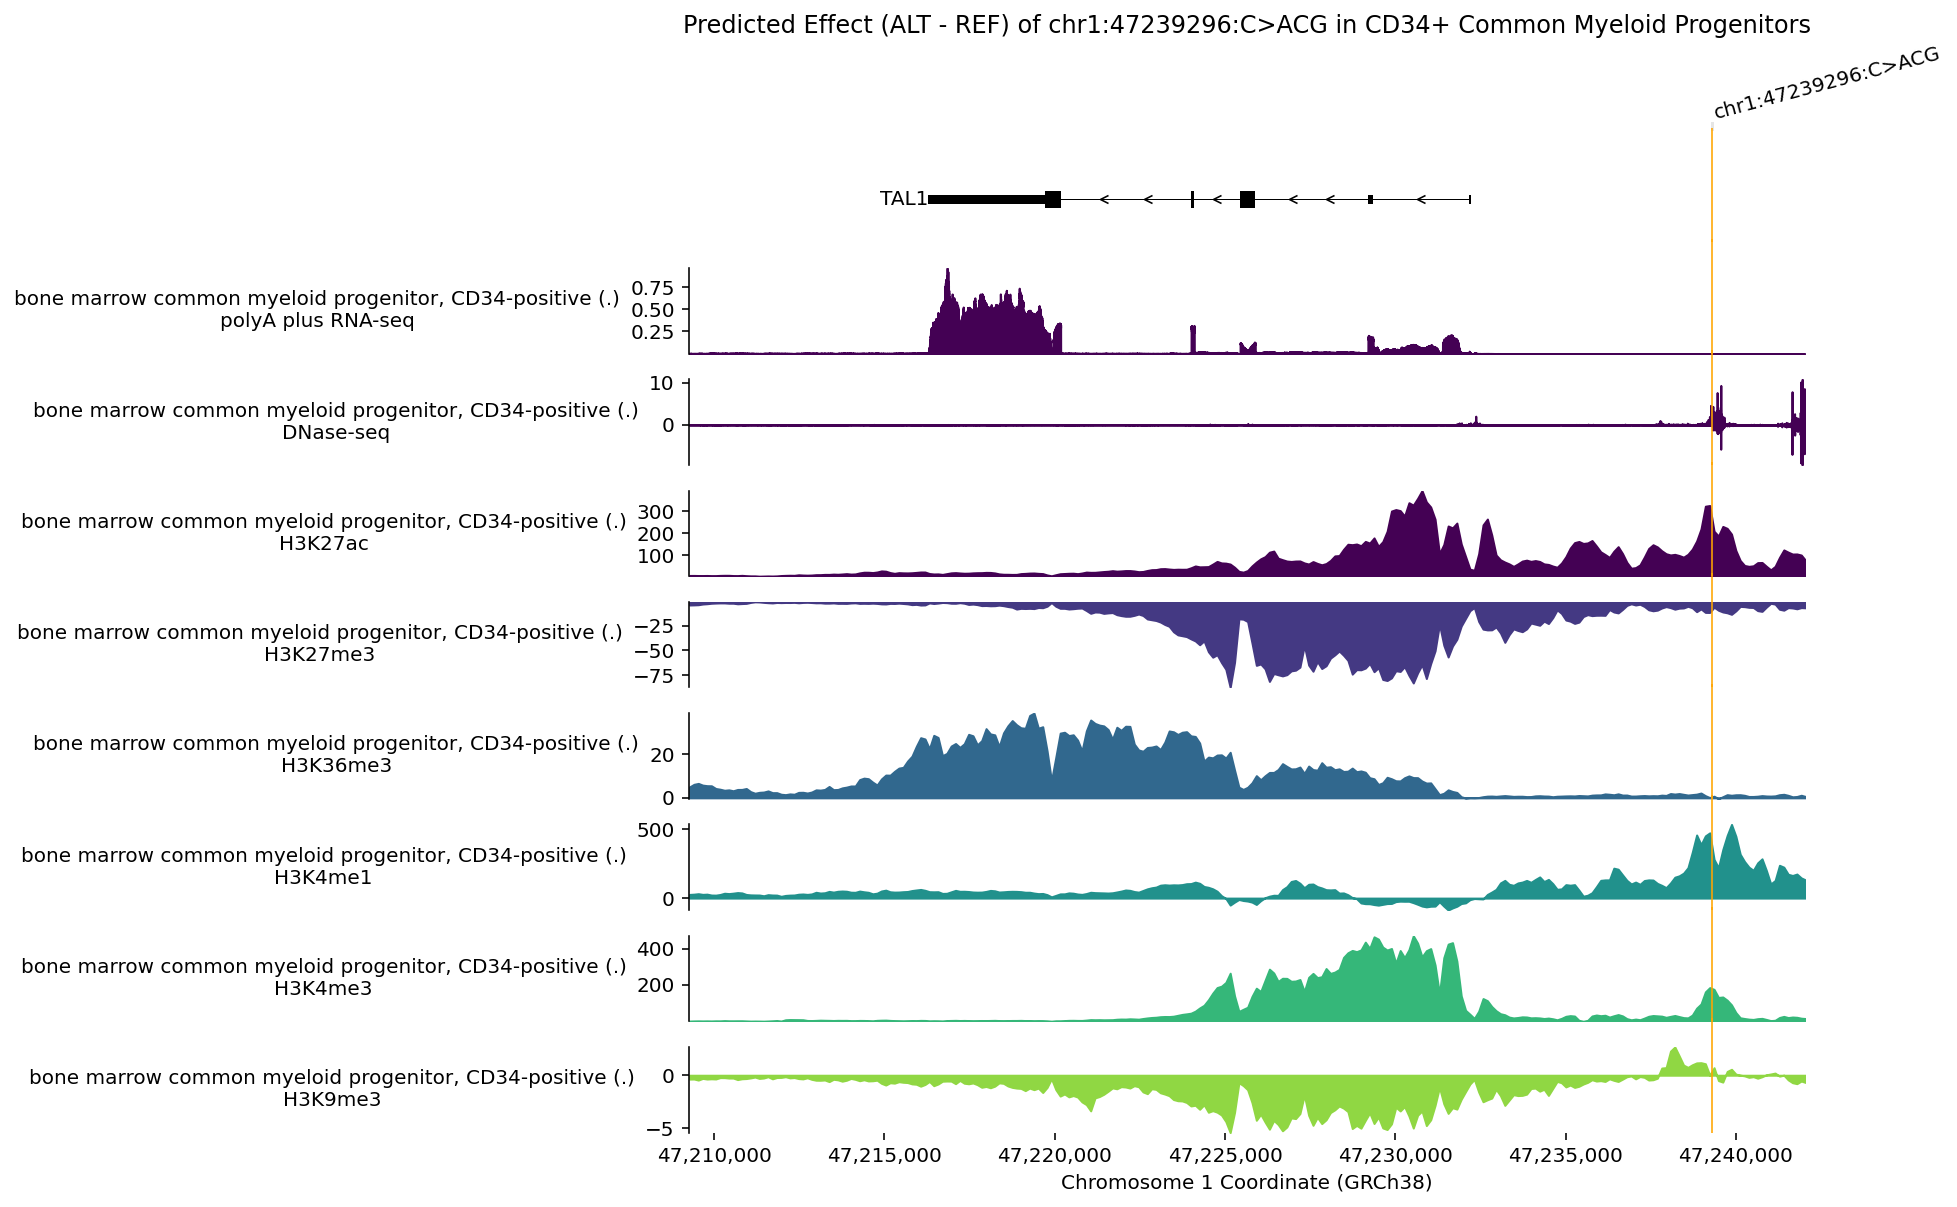

In [5]:
# @title Plot predicted track differences (ALT - REF) across RNA-seq, DNase-seq, and histone ChIP-seq
tal1_interval = genome.Interval('chr1', 47_209_255, 47_242_023)

fig = plot_components.plot(
    [
        plot_components.TranscriptAnnotation(
            transcript_extractor.extract(tal1_interval)
        ),
        plot_components.Tracks(
            tdata=alt_obs.rna_seq - ref_obs.rna_seq,
            ylabel_template='{biosample_name} ({strand})\n{Assay title}',
            filled=True,
        ),
        plot_components.Tracks(
            tdata=alt_obs.dnase[:, :1] - ref_obs.dnase[:, :1],
            ylabel_template='{biosample_name} ({strand})\n{Assay title}',
            filled=True,
        ),
        plot_components.Tracks(
            tdata=alt_obs.chip_histone - ref_obs.chip_histone,
            ylabel_template='{biosample_name} ({strand})\n{histone_mark}',
            filled=True,
        ),
    ],
    annotations=[plot_components.VariantAnnotation([lead_variant])],
    interval=tal1_interval,
    fig_width=10,
    xlabel='Chromosome 1 Coordinate (GRCh38)',
    title='Predicted Effect (ALT - REF) of chr1:47239296:C>ACG in CD34+ Common Myeloid Progenitors',
)
fig.axes[-1].xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, _: f'{int(x):,}')
)
plt.show()

## Comparing T-ALL mutations with length-matched random alleles

We pair each of the 15 unique T-ALL alleles with up to six length-matched random alternate alleles at the same genomic position (excluding `REF` and observed T-ALL alleles) and score every candidate across a 1 Mb context using `variant_scorers.RECOMMENDED_VARIANT_SCORERS['RNA_SEQ']`.

In [6]:
# @title Score unique T-ALL alleles and length-matched random alleles at the same positions
unique_df = variants_df.drop_duplicates(subset=['CHROM', 'POS', 'REF', 'ALT'])
rng = np.random.default_rng(42)
bases = np.array(list('ACGT'))
seen = set(zip(unique_df['POS'], unique_df['ALT']))

rows = []
for r in unique_df.itertuples(index=False):
  rows.append({
      'CHROM': r.CHROM,
      'POS': r.POS,
      'REF': r.REF,
      'ALT': r.ALT,
      'is_oncogenic': True,
  })
  alt_len = len(r.ALT)
  pool = (
      list('ACGT')
      if alt_len == 1
      else [''.join(rng.choice(bases, size=alt_len)) for _ in range(15)]
  )
  added = 0
  for alt in pool:
    if alt != r.REF and (r.POS, alt) not in seen:
      rows.append({
          'CHROM': r.CHROM,
          'POS': r.POS,
          'REF': r.REF,
          'ALT': alt,
          'is_oncogenic': False,
      })
      seen.add((r.POS, alt))
      added += 1
      if added == 6:
        break

eval_df = pd.DataFrame(rows)
eval_df['variant'] = [
    genome.Variant(r.CHROM, int(r.POS), r.REF, r.ALT)
    for r in eval_df.itertuples(index=False)
]

scores = dna_model.score_variants(
    intervals=[
        v.reference_interval.resize(dna_client.SEQUENCE_LENGTH_1MB)
        for v in eval_df['variant']
    ],
    variants=eval_df['variant'].tolist(),
    variant_scorers=[variant_scorers.RECOMMENDED_VARIANT_SCORERS['RNA_SEQ']],
    conditions=[condition] * len(eval_df),
    max_workers=5,
)
tal1_idx = scores[0][0].obs.query('gene_name == "TAL1"').index[0]
track_idx = (
    scores[0][0]
    .var.query(
        '`Assay title` == "polyA plus RNA-seq" and endedness == "paired" and'
        ' data_pipeline == "encode"'
    )
    .index[0]
)
eval_df['raw_score'] = [
    float(s[0][tal1_idx, track_idx].X[0, 0]) for s in scores
]

  0%|          | 0/101 [00:00<?, ?it/s]

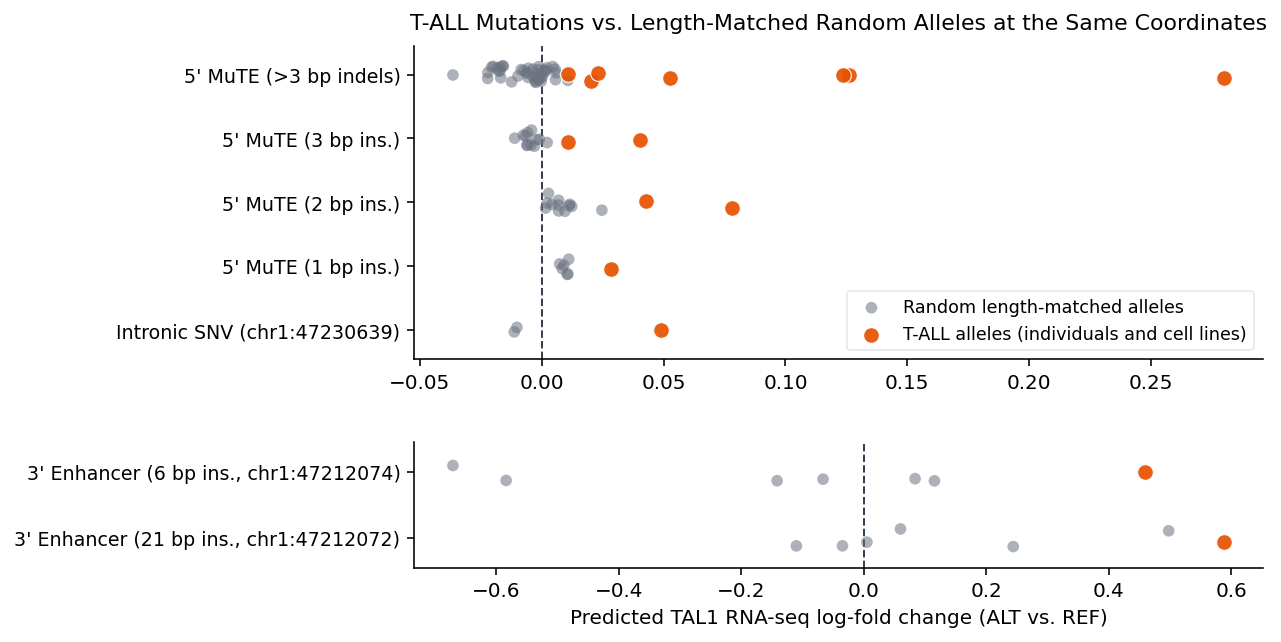

In [7]:
# @title Plot predicted TAL1 RNA-seq log-fold change across T-ALL and random alleles
def _variant_group(row):
  alt_len = len(row.ALT)
  if row.POS >= 47239290:
    return (
        "5' MuTE (>3 bp indels)"
        if alt_len > 4
        else f"5' MuTE ({alt_len - 1} bp ins.)"
    )
  if row.POS == 47230639:
    return 'Intronic SNV (chr1:47230639)'
  return f"3' Enhancer ({alt_len - 1} bp ins., chr1:{row.POS})"


eval_df['group'] = eval_df.apply(_variant_group, axis=1)

TOP_GROUPS = [
    "5' MuTE (>3 bp indels)",
    "5' MuTE (3 bp ins.)",
    "5' MuTE (2 bp ins.)",
    "5' MuTE (1 bp ins.)",
    'Intronic SNV (chr1:47230639)',
]
BOTTOM_GROUPS = [
    "3' Enhancer (6 bp ins., chr1:47212074)",
    "3' Enhancer (21 bp ins., chr1:47212072)",
]

fig, (ax_top, ax_bot) = plt.subplots(
    2,
    1,
    figsize=(7.6, 4.8),
    gridspec_kw={'height_ratios': [5, 2], 'hspace': 0.38},
)
rng_plot = np.random.default_rng(0)

for ax, groups in [(ax_top, TOP_GROUPS), (ax_bot, BOTTOM_GROUPS)]:
  sub = eval_df[eval_df['group'].isin(groups)]
  y_map = {g: i for i, g in enumerate(groups)}
  bg = sub[~sub['is_oncogenic']]
  onc = sub[sub['is_oncogenic']]

  ax.scatter(
      bg['raw_score'],
      [y_map[g] + j for g, j in zip(bg['group'], rng_plot.uniform(-0.14, 0.14, len(bg)))],
      color='#6b7280',
      alpha=0.55,
      s=34,
      edgecolors='none',
      label='Random length-matched alleles',
      zorder=2,
  )
  ax.scatter(
      onc['raw_score'],
      [y_map[g] + j for g, j in zip(onc['group'], rng_plot.uniform(-0.10, 0.10, len(onc)))],
      color='#e65100',
      alpha=0.92,
      s=62,
      edgecolors='white',
      linewidths=0.6,
      label='T-ALL alleles (individuals and cell lines)',
      zorder=4,
  )
  ax.axvline(0.0, color='#374151', linestyle='--', linewidth=1.0, zorder=1)
  ax.set_yticks(range(len(groups)))
  ax.set_yticklabels(groups, fontsize=9.5)
  ax.set_ylim(-0.45, len(groups) - 0.55)
  ax.invert_yaxis()
  ax.spines['top'].set_visible(False)
  ax.spines['right'].set_visible(False)

ax_top.set_title(
    'T-ALL Mutations vs. Length-Matched Random Alleles at the Same Coordinates',
    fontsize=11,
    pad=8,
)
ax_top.legend(
    frameon=True,
    facecolor='white',
    edgecolor='#e5e7eb',
    fontsize=8.8,
    loc='lower right',
)
ax_bot.set_xlabel('Predicted TAL1 RNA-seq log-fold change (ALT vs. REF)', fontsize=10)
plt.show()

Across all seven variant groups, every somatic T-ALL mutation is predicted to increase *TAL1* transcription, and by more than the length-matched random alleles at the same coordinate:

- **5' MuTE neo-enhancer (`chr1:47,239,291` to `chr1:47,239,296`)**: Short 1-bp to 3-bp insertions (`C>AC`, `C>ACC`, `C>ACG`, `C>AACC`, `C>AACG`) and longer insertions from individuals with T-ALL create *de novo* MYB recognition motifs (`5'-ACCGTT-3'` / `5'-CAACG-3'`) that recruit MYB together with hematopoietic transcription factors (GATA3, RUNX1, TAL1, and CBP) to establish an H3K27ac/H3K4me1 enhancer, clear repressive H3K27me3 across the locus, and drive *TAL1* transcription ([Mansour et al., *Science* 2014](https://doi.org/10.1126/science.1259037); [Avsec et al., *Nature* 2026](https://doi.org/10.1038/s41586-025-10014-0)).
- **Intronic SNV (`chr1:47,230,639:C>T`) and 3' neo-enhancer insertions (`chr1:47,212,072` and `chr1:47,212,074`)**: Independent mutations in individuals with T-ALL inside intron 1 ([Liu et al., *Nature Genetics* 2020](https://doi.org/10.1038/s41588-020-0659-5)) and ~4 kb downstream of *TAL1* ([Smith et al., *Haematologica* 2023](https://doi.org/10.3324/haematol.2022.281583)) converge on the same transcriptional outcome, while matched random insertions at the same coordinates scatter around zero.